In [54]:
#그래프관련 import
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures    # 다항특성 자동생성
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_absolute_error         # 평균절대값오차 오차범위
from sklearn.preprocessing import StandardScaler        # 정규화 클래스


In [55]:
# 무게 데이터
perch_weight = [5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0, 85.0,
    110.0, 115.0, 125.0, 130.0, 120.0, 120.0, 130.0, 135.0, 110.0,
    130.0, 150.0, 145.0, 150.0, 170.0, 225.0, 145.0, 188.0, 180.0,
    197.0, 218.0, 300.0, 260.0, 265.0, 250.0, 250.0, 300.0, 320.0,
    514.0, 556.0, 840.0, 685.0, 700.0, 700.0, 690.0, 900.0, 650.0,
    820.0, 850.0, 900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0,
    1000.0, 1000.0]

In [56]:
df = pd.read_csv('data/perch_full.csv')
df.head(2)

,length,height,width
0,8.4,2.11,1.41
1,13.7,3.53,2.00


In [57]:
# 데이터 전처리
# 학습데이터, 테스트데이터 분리
train_data,test_data,train_label,test_label = train_test_split(df,perch_weight,random_state=42)
train_data[:2]

,length,height,width
8,19.6,5.14,3.04
17,22.0,5.88,3.52


In [58]:
# 특성값 추가 - degree=2
poly = PolynomialFeatures(degree=4,include_bias=False) # include_bias = False 기본값 1제외
poly.fit(train_data)
train_poly = poly.transform(train_data)
test_poly = poly.transform(test_data)

In [74]:
poly.get_feature_names_out()
train_poly.shape

(42, 34)

In [60]:
# 규제 정규화
ss = StandardScaler()
ss.fit(train_poly)
train_scaled = ss.transform(train_poly)
test_scaled = ss.transform(test_poly)




In [64]:
# 규제의 강도를 높여서 확인.
alpha_list = [0.001,0.01,0.1,0,1,10,100]

train_score = []
test_score = []

for alpha in alpha_list:
    lasso = Lasso(alpha=alpha)
    lasso.fit(train_scaled,train_label)
    score = lasso.score(train_scaled,train_label)
    score2 = lasso.score(test_scaled,test_label)
    train_score.append(score)
    test_score.append(score2)



c:\python313\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.454e+04, tolerance: 5.183e+02
  model = cd_fast.enet_coordinate_descent(
c:\python313\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.926e+04, tolerance: 5.183e+02
  model = cd_fast.enet_coordinate_descent(
c:\python313\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.424e+03, tolerance: 5.183e+02
  model = cd_fast.enet_

In [66]:
no_list = list(range(1,8))
no_list

[1, 2, 3, 4, 5, 6, 7]

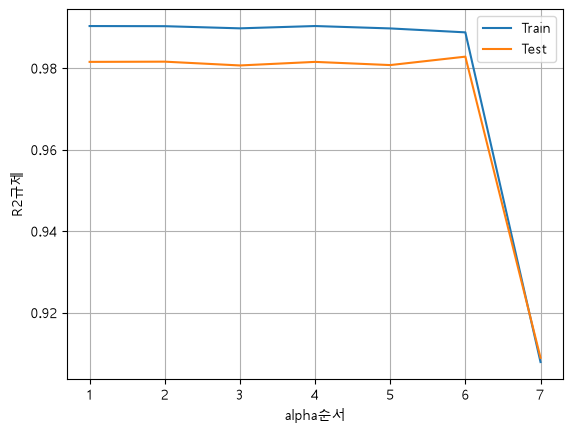

In [70]:
no_list = list(range(1,8))
plt.plot(no_list,train_score)
plt.plot(no_list,test_score)
plt.grid()
plt.legend(['Train','Test'])
plt.xlabel('alpha순서')
plt.ylabel('R2규제')
plt.show()

In [72]:
lasso = Lasso(alpha=10)
lasso.fit(train_scaled,train_label)
score = lasso.score(train_scaled,train_label)
score2 = lasso.score(test_scaled,test_label)
print('train정확도 : ',score)
print('test정확도 : ',score2)
print(np.sum(lasso.coef_))

train정확도 :  0.9887592776354638
test정확도 :  0.9827993522166355
341.7078245949342


In [62]:
lr = LinearRegression()
lr.fit(train_poly,train_label)
score = lr.score(train_poly,train_label)
score2 = lr.score(test_poly,test_label)
print('train정확도 : ',score)
print('test정확도 : ',score2)

train정확도 :  0.999528689807397
test정확도 :  -6.786696920351177
